# Unsplash Lite: UMAP on DINOv2 image embeddings (extra example)

An extra example that is **not in the post**: the same pipeline as the [Open Images example](openimages_umap.ipynb) ([in the post](https://gprietos.github.io/posts/umap/#open-images-dataset)), on the 25,000 photos of Unsplash Lite. These are curated photos, mostly of a single subject, unlike Open Images' cluttered snapshots, and instead of object labels each photo has keywords.

The notebook:
1. embeds the photos with DINOv2 and computes 2-D and 3-D UMAP maps.
2. shows the map without labels, as on unlabeled data, and looks at the photos in some of its islands.
3. colors the map by the photos' Unsplash keywords. They come from Unsplash, not from the model, so they are an independent check of what the embedding puts together.
4. shows the 3-D map.

**Before running:** download Unsplash Lite from [unsplash.com/data](https://unsplash.com/data) (you have to accept its terms), put or symlink the extracted folder at `data/unsplash/`, and download the images with `uv run python scripts/download_unsplash.py` (about 2.5 GB, resumable).

**Warning:** embedding takes a few minutes on a GPU and much longer on a CPU. Embeddings (field `emb_dinov2_vitb14`) and UMAP results (brain runs) are stored in the persistent FiftyOne dataset `unsplash-lite`, so later runs only load them.

**License:** the Unsplash Lite terms allow downloading the data and using it internally, but not sharing it, so this notebook will not show outputs with photos.

In [ ]:
import fiftyone as fo
import matplotlib.pyplot as plt
import numpy as np

from umap_examples.config import FIGURES_DIR, SEED
from umap_examples.embeddings import MODELS, embed
from umap_examples.plotting import draw_boxes, plot_3d, plot_image_grid, plot_scatter, save_figure
from umap_examples.reduction import points_in_box, umap_run
from umap_examples.unsplash import keyword_labels, load_dataset

## Config

In [ ]:
# Embedding model
MODEL = "dinov2_vitb14"  # one of MODELS

# UMAP hyperparameters
N_NEIGHBORS = 15
MIN_DIST = 0.1

# Islands of the 2-D map, as boxes (x0, x1, y0, y1). They only fit this model and these UMAP parameters.
REGIONS = {
    "dogs": (10.3, 13.6, -3.2, -1.0),
    "cats": (9.3, 10.6, -4.2, -3.0),
    "night sky": (1.2, 3.0, 10.8, 13.6),
    "cities": (10.4, 11.4, 11.4, 12.4),
}

# Keywords for the coloring: a photo gets the first one it has, the rest are "other".
KEYWORDS = ["dog", "cat", "bird", "horse", "boat", "car", "food", "flower", "desert"]

# Launch the FiftyOne App at the end?
INTERACTIVE = True

print(list(MODELS))

## Dataset and embeddings

Only new images are added to the dataset, and only samples without an embedding are embedded.

In [ ]:
dataset = load_dataset()
field = embed(dataset, MODEL)
dataset

Name:        unsplash-lite
Media type:  image
Num samples: 24997
Persistent:  True
Tags:        []
Sample fields:
    id:                fiftyone.core.fields.ObjectIdField
    filepath:          fiftyone.core.fields.StringField
    tags:              fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:          fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:        fiftyone.core.fields.DateTimeField
    last_modified_at:  fiftyone.core.fields.DateTimeField
    photo_id:          fiftyone.core.fields.StringField
    description:       fiftyone.core.fields.StringField
    ai_description:    fiftyone.core.fields.StringField
    keywords:          fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    country:           fiftyone.core.fields.StringField
    photographer:      fiftyone.core.fields.StringField
    emb_dinov2_vitb14: fiftyone.core.fields.VectorField
    cluster_id:        fiftyone.core.fie

## UMAP

A 2-D run for the plots (also shown in the App's Embeddings panel) and a 3-D run for the interactive view at the end.

In [ ]:
points = umap_run(dataset, field, n_neighbors=N_NEIGHBORS, min_dist=MIN_DIST)
points_3d = umap_run(dataset, field, num_dims=3, n_neighbors=N_NEIGHBORS, min_dist=MIN_DIST)
dataset.list_brain_runs()

['umap_dinov2_vitb14',
 'umap_emb_clip_vitb32_2d_k15_md01',
 'umap_emb_dinov2_vitb14_2d_k15_md00',
 'umap_emb_dinov2_vitb14_2d_k15_md01',
 'umap_emb_dinov2_vitb14_2d_k15_md05',
 'umap_emb_dinov2_vitb14_2d_k200_md00',
 'umap_emb_dinov2_vitb14_2d_k200_md01',
 'umap_emb_dinov2_vitb14_2d_k200_md05',
 'umap_emb_dinov2_vitb14_2d_k50_md00',
 'umap_emb_dinov2_vitb14_2d_k50_md01',
 'umap_emb_dinov2_vitb14_2d_k50_md05',
 'umap_emb_dinov2_vitb14_2d_k5_md00',
 'umap_emb_dinov2_vitb14_2d_k5_md01',
 'umap_emb_dinov2_vitb14_2d_k5_md05',
 'umap_emb_dinov2_vitb14_3d_k15_md01']

## Map without labels

This is what you get on unlabeled data: islands and a large connected region. The sizes of the islands and the gaps between them depend on `n_neighbors` and `min_dist`, and the distances between islands don't mean much.

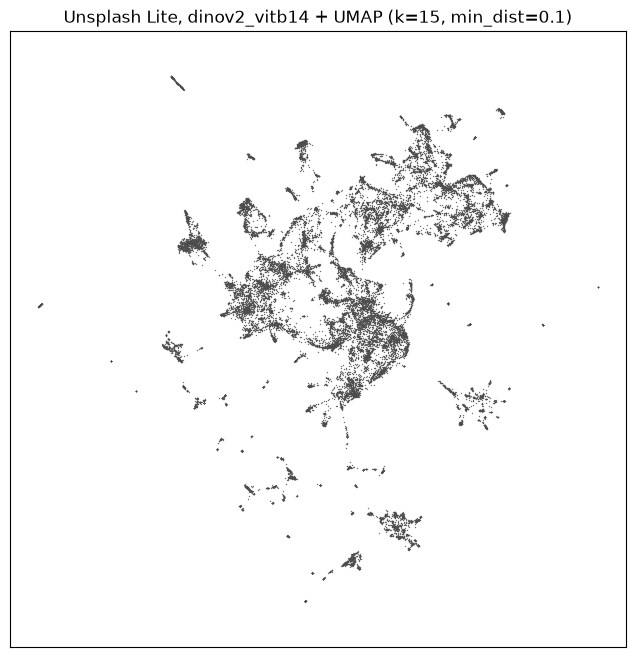

In [ ]:
ax = plot_scatter(points, s=1)
ax.set_title(f"Unsplash Lite, {MODEL} + UMAP (k={N_NEIGHBORS}, min_dist={MIN_DIST})")
save_figure(ax.figure, f"unsplash_{MODEL}_unlabeled")
plt.show()

## What's in the islands

The boxes in `REGIONS`, drawn on the map with ticks to help pick them, then a random sample of photos from each. Each region is also saved as a FiftyOne view (`region-<name>`) to open in the App.

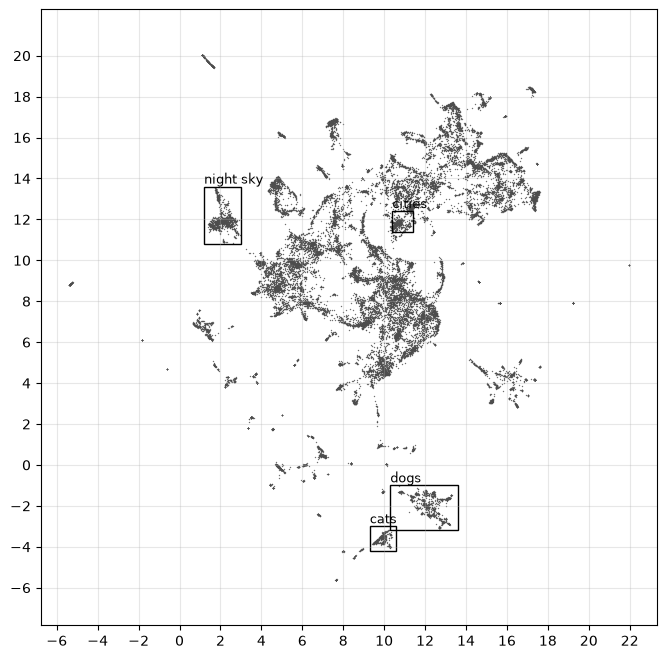

In [ ]:
ax = plot_scatter(points, s=1)
draw_boxes(ax, REGIONS)
ax.set(xticks=np.arange(np.floor(points[:, 0].min()), points[:, 0].max() + 1, 2),
       yticks=np.arange(np.floor(points[:, 1].min()), points[:, 1].max() + 1, 2))
ax.grid(alpha=0.3)
plt.show()

In [ ]:
rng = np.random.default_rng(SEED)
ids = np.array(dataset.values("id"))
filepaths = np.array(dataset.values("filepath"))
for name, box in REGIONS.items():
    idx = points_in_box(points, box)
    dataset.save_view(f"region-{name.replace(' ', '-')}", dataset.select(ids[idx].tolist()), overwrite=True)
    sample = rng.choice(idx, min(18, len(idx)), replace=False)
    fig = plot_image_grid(filepaths[sample], title=f"{name} ({len(idx)} photos)")
    save_figure(fig, f"unsplash_{MODEL}_region_{name.replace(' ', '_')}")
    plt.show()

## Map colored by keyword

The independent check: do Unsplash's keywords agree with the islands found by eye?

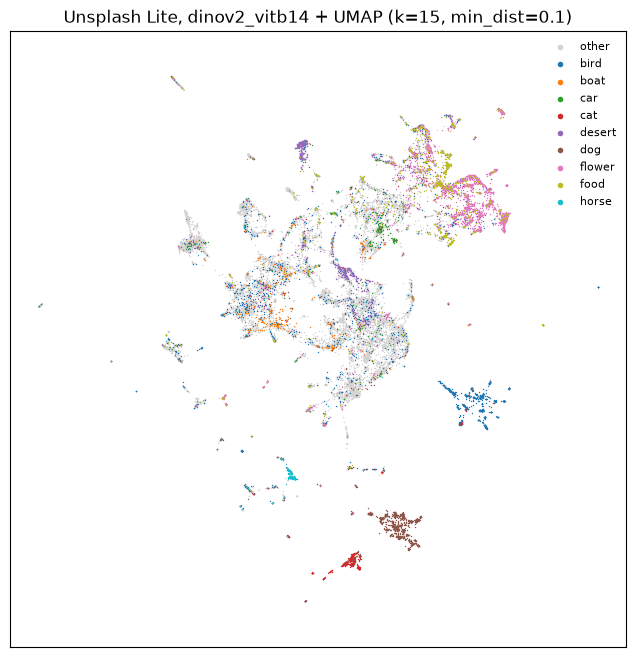

In [ ]:
labels = keyword_labels(dataset.values("keywords"), KEYWORDS)
dataset.set_values("keyword_label", labels)

ax = plot_scatter(points, labels, s=1)
ax.set_title(f"Unsplash Lite, {MODEL} + UMAP (k={N_NEIGHBORS}, min_dist={MIN_DIST})")
save_figure(ax.figure, f"unsplash_{MODEL}_keywords")
plt.show()

Note that the islands come from DINOv2, not from UMAP. DINOv2's distances put these photos together, and UMAP only represents the neighbor graph they define. Like any UMAP map, this one comes with the [weaknesses](https://gprietos.github.io/posts/umap/#umap-weaknesses) of the method, so splits, gaps and island sizes shouldn't be read as facts about the data.

## 3-D map

The 3-D UMAP, colored by keyword. Drag to rotate, hover a point to read the photo's description, and click a keyword in the legend to hide or show it. It is also saved as a standalone HTML file in `outputs/figures/`.

In [ ]:
fig = plot_3d(points_3d, labels, hover=[d or "" for d in dataset.values("ai_description")])
fig.write_html(FIGURES_DIR / f"unsplash_{MODEL}_umap3d.html")
fig.show()

## Browse in FiftyOne

To analyze the map further, the FiftyOne App shows the UMAP layout next to the photos. After running the cell below:

1. **Open the Embeddings panel:** click the **+** next to the **Samples** tab at the top and choose **Embeddings**.
2. **Pick a layout:** in the panel's first dropdown, choose the 2-D run, `umap_emb_dinov2_vitb14_2d_k15_md01`.
3. **Color the points:** in **Color by**, choose `keyword_label` to color each photo by its keyword.
4. **See the photos:** lasso a region of the plot, and the grid shows only those photos.
5. **Show only one keyword:** in the sidebar on the left, open the dropdown menu that contains `keyword_label`, click the field and tick a keyword (for example dog). Only those photos remain, in the grid and in the plot.
6. **Open a region:** the islands from `REGIONS` are saved as views (`region-dogs`, `region-cats`, ...). Pick one in the saved views dropdown above the grid.

In [ ]:
if INTERACTIVE:
    session = fo.launch_app(dataset)